# Notebook to look at preliminary bee recordings

Lily and Luke mention that they cannot hear bee wingbeat in first test recordings, but I think it's there? Want to try to filter out AC fan. To do this, use the trials in which the bee didn't fly well (trials 1-3, 6)

## Imports

In [12]:
import os
import glob
import librosa

import numpy as np
from matplotlib import rcParams
import matplotlib.pyplot as plt

from scipy import signal 
from pathlib import Path


## Helper functions

## Load data

In [23]:
# paht to data 
data_root = Path(r'C:\Users\samcw\Dropbox\bee_recordings')
expr_folder = '01_20260929'
ext = '.mp3'

file_ind = 4

In [24]:
# get list of files
audio_files = list((data_root / expr_folder).glob(f'*{ext}'))


In [25]:
# load one file
file_curr = audio_files[file_ind]
print(file_curr)

sig, fs = librosa.load(file_curr, sr=None) 

# import librosa

# # Load the MP3 file
# file_path = "your_audio_file.mp3"
# y, sr = librosa.load(file_path, sr=None) 

# # y = audio time-series (numpy array)
# # sr = sampling rate

C:\Users\samcw\Dropbox\bee_recordings\01_20260929\260929_1307.mp3


## Plot data

Text(0, 0.5, 'mic (V)')

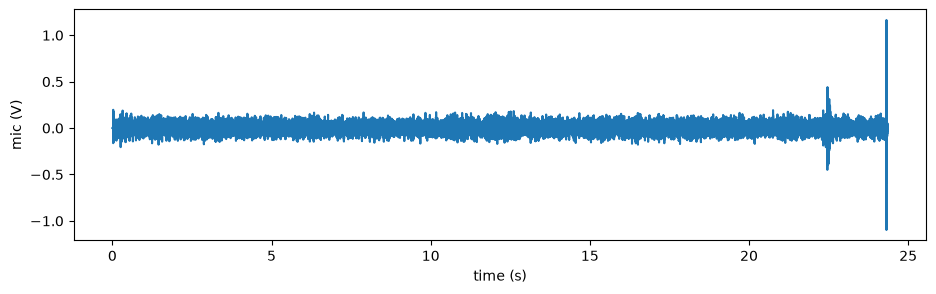

In [26]:
# make a plot of raw audio signal
t = (1/fs)*np.arange(sig.size)
fig, ax = plt.subplots(figsize=(11,3))

ax.plot(t, sig)
ax.set_xlabel('time (s)')
ax.set_ylabel('mic (V)')

Text(0, 0.5, 'PSD [V**2/Hz]')

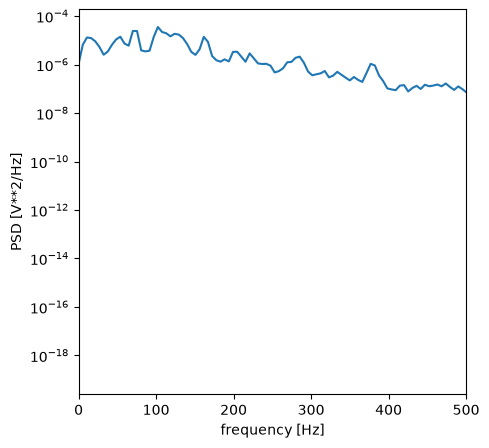

In [31]:
# plot power spectrum of full recording
f, Pxx_den = signal.welch(sig, fs, nperseg=1024*8)

fig, ax = plt.subplots(figsize=(5,5))
ax.semilogy(f, Pxx_den)
ax.set_xlim([0, 500])
ax.set_xlabel('frequency [Hz]')
ax.set_ylabel('PSD [V**2/Hz]')

Text(0.5, 0, 'Time (s)')

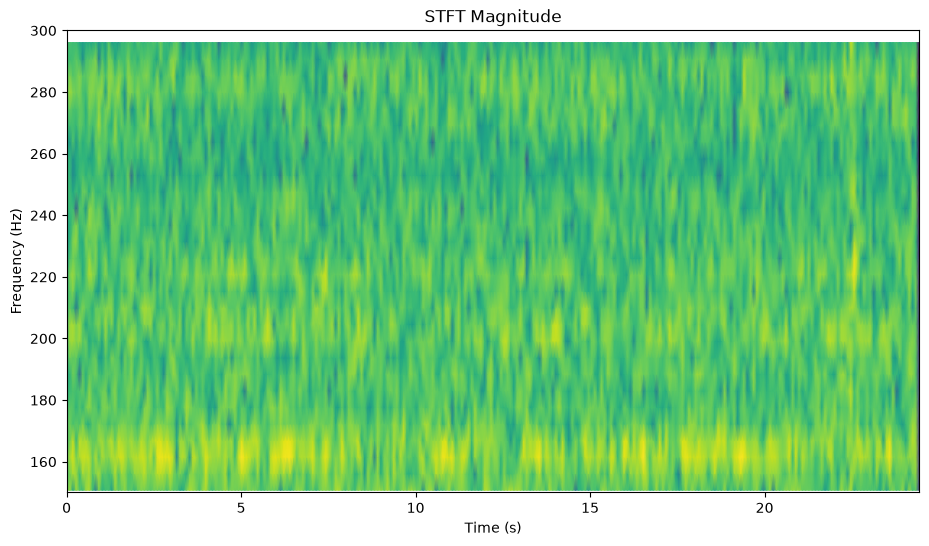

In [40]:
# look at spectrogram
MIN_F = None
MAX_F = None
NPERSEG = 8*1024

freq, t, Zxx = signal.stft(sig, fs, nperseg=NPERSEG)

# # restrict attention to frequencies < max_freq
if MAX_F is not None:
    keep_idx = (freq <= MAX_F)
    freq = freq[keep_idx]
    Zxx = Zxx[keep_idx, :]

if MIN_F is not None:
    keep_idx = (freq >= MIN_F)
    freq = freq[keep_idx]
    Zxx = Zxx[keep_idx, :]
    
# # get max vals at each time point
# freq_max_idx = np.argmax(np.abs(Zxx), axis=0)
# freq_max = freq[freq_max_idx]

# # upsample estimated wbf to full time range
# t_full = (1 / abf_dict['sampling_freq']) * np.arange(abf_dict['mic'].size)
# wbf = np.interp(t_full, t, freq_max)

# make figure
fig, ax = plt.subplots(figsize=(11, 6))

# plot data
ax.pcolormesh(t, freq, np.abs(Zxx), shading='gouraud', norm='log')  # , cmap = plt.colormaps["plasma"])
# ax.plot(t_full, wbf, 'r-')

ax.set_ylim([MIN_F, MAX_F])
# label axes
ax.set_title('STFT Magnitude')
ax.set_ylabel('Frequency (Hz)')
ax.set_xlabel('Time (s)')